In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df=pd.read_csv("diabetes_patients_10000_full.csv")
df.head()

,Patient_ID,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,1,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,2,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,3,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,4,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,5,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         10000 non-null  int64  
 1   Age                9986 non-null   float64
 2   Gender             9960 non-null   str    
 3   Blood_Sugar_Level  9947 non-null   float64
 4   Creatinine         9944 non-null   float64
 5   BMI                9949 non-null   float64
 6   Urea               9949 non-null   float64
 7   Cholesterol        9968 non-null   float64
 8   HbA1c              10000 non-null  float64
 9   Class              10000 non-null  str    
dtypes: float64(7), int64(1), str(2)
memory usage: 912.8 KB


In [4]:
df.describe()

,Patient_ID,Age,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c
count,10000.00000,9986.000000,9947.000000,9944.000000,9949.000000,9949.000000,9968.000000,10000.000000
mean,5000.50000,49.957240,169.255454,1.100253,26.746959,35.121520,225.311196,7.503780
std,2886.89568,17.630097,46.059059,0.286964,4.787215,11.829985,43.806703,1.743745
min,1.00000,20.000000,90.000000,0.600000,18.500000,15.000000,150.000000,4.500000
25%,2500.75000,35.000000,130.000000,0.850000,22.600000,25.000000,187.000000,6.000000
50%,5000.50000,50.000000,169.000000,1.100000,26.700000,35.000000,225.000000,7.500000
75%,7500.25000,65.000000,209.000000,1.350000,31.000000,45.000000,263.000000,9.000000
max,10000.00000,80.000000,250.000000,1.600000,35.000000,55.000000,300.000000,10.500000


In [5]:
df.shape

(10000, 10)

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.isnull().sum().sort_values(ascending=False)

Creatinine           56
Blood_Sugar_Level    53
BMI                  51
Urea                 51
Gender               40
Cholesterol          32
Age                  14
Patient_ID            0
HbA1c                 0
Class                 0
dtype: int64

In [8]:
df.dropna(inplace=True)

In [9]:
df.isnull().sum().sort_values(ascending=False)

Patient_ID           0
Age                  0
Gender               0
Blood_Sugar_Level    0
Creatinine           0
BMI                  0
Urea                 0
Cholesterol          0
HbA1c                0
Class                0
dtype: int64

In [10]:
df.select_dtypes(object).columns

C:\Users\abdoa\AppData\Local\Temp\ipykernel_8752\1734617840.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(object).columns


Index(['Gender', 'Class'], dtype='str')

In [11]:
df.drop(['Patient_ID'],axis=1,inplace=True)

In [12]:
df.reset_index(drop=True,inplace=True)

<Axes: xlabel='Gender', ylabel='Class'>

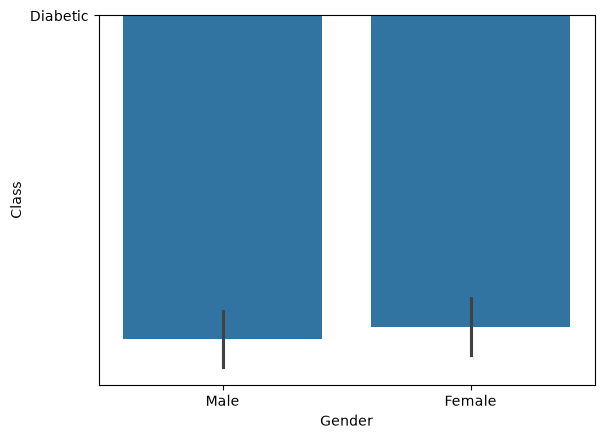

In [13]:
sns.barplot(data=df,x='Gender',y='Class')

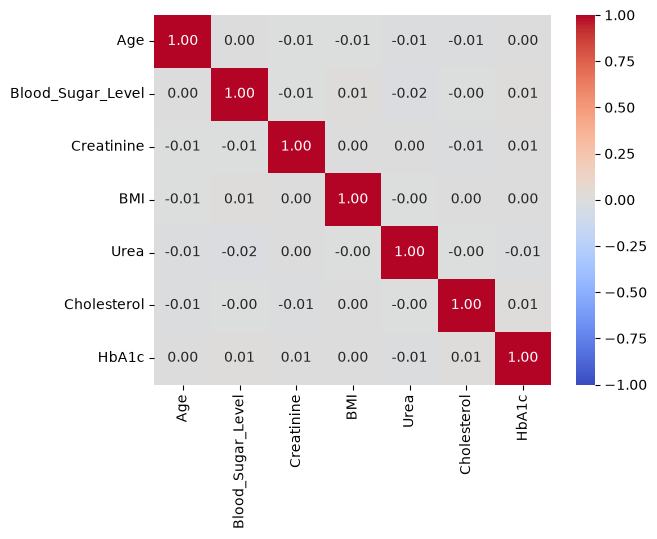

In [14]:
corr = df.select_dtypes(
    include="number"
).corr()

sns.heatmap(
    corr, annot=True, fmt='.2f',
    cmap="coolwarm", vmin=-1, vmax=1
)
plt.show()

In [15]:
from sklearn.preprocessing import OneHotEncoder
ohe=OneHotEncoder(sparse_output=False,
                  drop='first',
                   handle_unknown='ignore'
                  ).set_output(transform='pandas')

In [16]:
temp=ohe.fit_transform(df[['Gender']])

In [17]:
df=pd.concat([df,temp],axis=1)

In [18]:
df.drop(['Gender'],axis=1,inplace=True)

In [19]:
df.head()


,Age,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class,Gender_Male
0,60.0,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic,1.0
1,77.0,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic,1.0
2,21.0,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic,1.0
3,30.0,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic,0.0
4,26.0,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic,0.0


In [20]:
X=df.drop(['Class'],axis=1)
y=df['Class']

In [21]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,
                                   test_size= 0.20, random_state=42, stratify=y)

In [22]:
from sklearn.preprocessing import StandardScaler
scal=StandardScaler()

In [23]:

X_train[['Blood_Sugar_Level']] = scal.fit_transform(X_train[['Blood_Sugar_Level']]) # X_train
X_test[['Blood_Sugar_Level']] = scal.transform(X_test[['Blood_Sugar_Level']]) # X_test

In [24]:

X_train[['Age']] = scal.fit_transform(X_train[['Age']]) # X_train
X_test[['Age']] = scal.transform(X_test[['Age']]) # X_test

In [25]:
from sklearn.preprocessing import StandardScaler
scal=StandardScaler()

In [26]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression(
    C=1.0,
max_iter=200,
penalty='l2'
)



In [27]:
model.fit(X_train,y_train)

c:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
 

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",200
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the opt

In [28]:
y_pred=model.predict(X_test)

In [29]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,\
    f1_score ,confusion_matrix,classification_report

In [30]:
acc=accuracy_score(y_test,y_pred)
print(acc)

0.9672873678912934


In [31]:
rec=recall_score(y_test,y_pred,average='macro')
print(rec)

0.8808054647285442


In [32]:
per=precision_score(y_test,y_pred,average='macro')
print(per)

0.9047004665373024


In [33]:
f=f1_score(y_test,y_pred,average='macro')
print(f)

0.8922994817399861


In [34]:
rep=classification_report(y_test,y_pred)
print(rep)

              precision    recall  f1-score   support

    Diabetic       0.98      0.99      0.98      1817
Non-Diabetic       0.83      0.78      0.80       170

    accuracy                           0.97      1987
   macro avg       0.90      0.88      0.89      1987
weighted avg       0.97      0.97      0.97      1987



In [35]:
from sklearn.neighbors import KNeighborsClassifier
model=KNeighborsClassifier(n_neighbors=5,metric='minkowski',p=1)

In [36]:
model.fit(X_train,y_train)


,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",1
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['Diabetic','Non-Diabetic']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'ma...an'


In [37]:
y_predd=model.predict(X_test)

In [38]:
rep=classification_report(y_test,y_predd)
print(rep)

              precision    recall  f1-score   support

    Diabetic       0.93      0.99      0.96      1817
Non-Diabetic       0.62      0.17      0.27       170

    accuracy                           0.92      1987
   macro avg       0.77      0.58      0.61      1987
weighted avg       0.90      0.92      0.90      1987



In [39]:
from sklearn.naive_bayes import GaussianNB

In [40]:
model=GaussianNB()

In [41]:
model.fit(X_train,y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[7266., 679.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.91,0.09]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[<U12](2,)","['Diabetic','Non-Diabetic']"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.915e-06
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['Age','Blood_Sugar_Level','Creatinine',...,'Cholesterol','HbA1c', 'Gender_Male']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 8)","[[ 0. , 0.11, 1.1 ,...,225.9 , 7.73, 0.49], [ -0.05, -1.17, 1.09,...,225.59, 5.25, 0.49]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 8)","[[ 1. , 0.94, 0.08,...,1923.67, 2.78, 0.25], [ 0.96, 0.1 , 0.08,...,1817.81, 0.2 , 0.25]]"


In [42]:
y_prd=model.predict(X_test)

In [43]:
rep=classification_report(y_test,y_prd)
print(rep)

              precision    recall  f1-score   support

    Diabetic       0.99      1.00      0.99      1817
Non-Diabetic       1.00      0.88      0.94       170

    accuracy                           0.99      1987
   macro avg       0.99      0.94      0.97      1987
weighted avg       0.99      0.99      0.99      1987



In [44]:
from sklearn.svm import SVC, SVR
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
model = SVC(kernel='linear', C=100, gamma=1,probability=True)

In [45]:
model.fit(X_train,y_train)

c:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",100
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",1
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [46]:
y_pred = model.predict(X_test)

In [47]:
rep=classification_report(y_test,y_pred)
print(rep)

              precision    recall  f1-score   support

    Diabetic       0.98      0.98      0.98      1817
Non-Diabetic       0.83      0.82      0.83       170

    accuracy                           0.97      1987
   macro avg       0.91      0.90      0.90      1987
weighted avg       0.97      0.97      0.97      1987



In [48]:
from sklearn.tree import DecisionTreeClassifier,plot_tree

In [49]:
model = DecisionTreeClassifier(

        # Split quality measure
        # "gini"      → Gini impurity (default, fast)
        # "entropy"   → Information gain (ID3 style)
        # "log_loss"  → Similar to entropy but probabilistic
        criterion='gini',


        random_state=100,


       
        min_samples_split=10,

        min_samples_leaf=5,

     
        min_impurity_decrease=0.01,

     ccp_alpha=0.01
        
    )



In [50]:
# Train model
model.fit(X_train, y_train)
y_pred_test  = model.predict(X_test)

Acc_Test  = accuracy_score(y_test, y_pred_test)

print(
    Acc_Test,  
)

1.0


Decision Tree - Plotting the tree


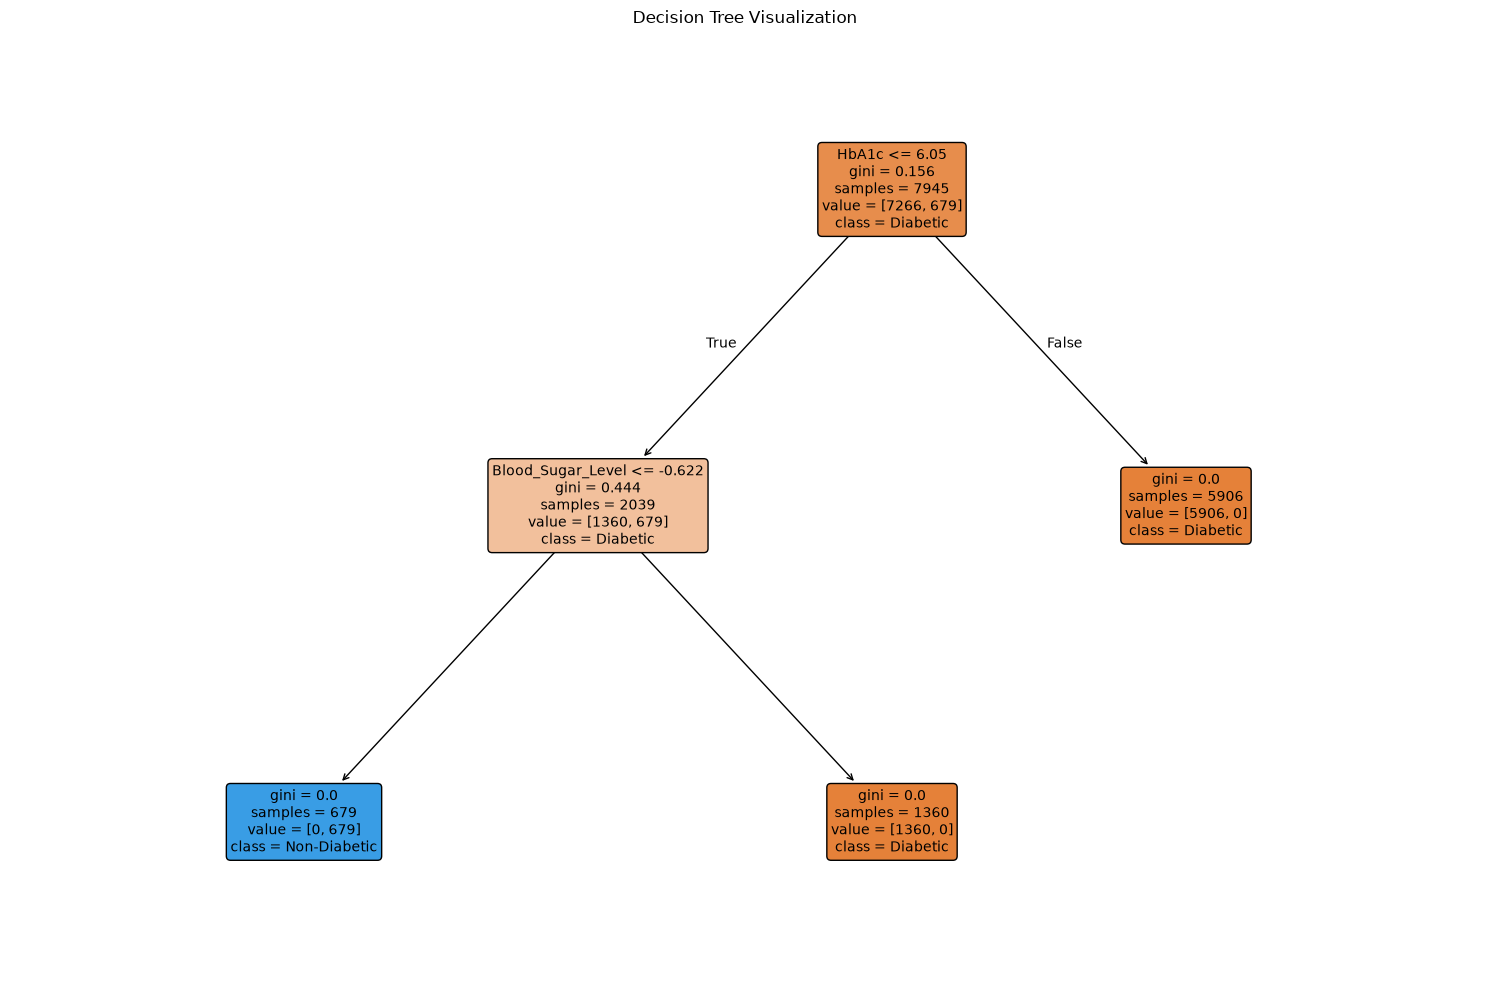

In [51]:
print("Decision Tree - Plotting the tree")

plt.figure(figsize=(15, 10))
plot_tree(
    model,
    feature_names=X.columns.tolist(),
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Visualization")
plt.tight_layout()
plt.show()

In [52]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score, StratifiedKFold
grid_params = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5]
}

In [53]:
grid = GridSearchCV(estimator=DecisionTreeClassifier(), param_grid=grid_params, cv=5, scoring='accuracy')

grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"

In [54]:
print(grid.best_params_)
print(grid.best_score_)


{'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
1.0


In [55]:
best_model = grid.best_estimator_


In [56]:
y_pred = best_model.predict(X_test)

print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

1.0
              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00      1817
Non-Diabetic       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

